# THÀNH VIÊN 5: PHÂN BỔ RỦI RO EULER, STRESS TESTING & TÍCH HỢP CODE

**Vị trí trong chuỗi:** TV3 `dcc_matrices.npz` ($H_t$) + TV4 `var_es_timeseries.csv`, `backtest_results.csv` → **TV5** → khuyến nghị quản trị

| Bước | Nội dung | File output |
|---|---|---|
| 0 | **Kiểm tra tích hợp**: đủ file, khớp ngày/mã, ma trận hợp lệ (+ tuỳ chọn chạy lại TV1→TV4) | `integration_check.csv` |
| 1 | Marginal VaR, Euler RC, kiểm chứng $\sum RC_i = VaR_p$, %RC theo ngày | `euler_rc_timeseries.csv` |
| 2 | Stress periods: Covid-19 (02–04/2020), Trái phiếu & lãi suất (04–11/2022) so với bình thường | `stress_comparison.xlsx` |
| 3 | Khuyến nghị: danh mục cân bằng rủi ro (risk parity) & tác động của correlation breakdown | `recommendations.txt` |

In [4]:
import subprocess
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from project_config import *

OUT_DIR = TV5_DIR

## 0. Tích hợp code (Code Integration)
Thứ tự chạy bắt buộc: **TV1 → TV2 → TV3 → TV4 → TV5**. Mỗi notebook chỉ đọc file "hợp đồng" (khai báo trong `project_config.FILES`) của bước trước.
Đặt `RUN_PIPELINE = True` để notebook này tự chạy lại TV1→TV4 (cần `jupyter nbconvert`); mặc định False – chỉ kiểm tra output đã có.

In [2]:
RUN_PIPELINE = False
NOTEBOOKS = ["TV1_Data_EDA.ipynb", "TV2_GARCH.ipynb", "TV3_DCC.ipynb", "TV4_VaR_Backtest.ipynb"]

if RUN_PIPELINE:
    code_dir = Path.cwd()
    for nb in NOTEBOOKS:
        print(f"▶ Đang chạy {nb} ...")
        out = subprocess.run([sys.executable, "-m", "jupyter", "nbconvert", "--to", "notebook", "--execute",
                              "--inplace", "--ExecutePreprocessor.timeout=1800", str(code_dir / nb)],
                             capture_output=True, text=True)
        if out.returncode != 0:
            raise RuntimeError(f"{nb} lỗi:\n{out.stderr[-3000:]}")
        print(f"  ✔ {nb} xong")

In [5]:
# ===================== 0b. KIỂM TRA FILE & TÍNH TƯƠNG THÍCH =====================
owner = {"prices": "TV1", "log_returns": "TV1", "garch_selected": "TV2", "std_resid": "TV2", "cond_vol": "TV2",
         "sigma_fcst": "TV2", "dcc_params": "TV3", "dcc_npz": "TV3", "dyn_corr": "TV3", "var_es": "TV4", "backtest": "TV4"}
checks = []
for key, path in FILES.items():
    checks.append({"Hạng mục": f"File {path.name}", "Thành viên": owner[key], "Đạt": path.exists(), "Ghi chú": str(path)})
missing = [c["Hạng mục"] for c in checks if not c["Đạt"]]
if missing:
    display(pd.DataFrame(checks))
    raise FileNotFoundError(f"Thiếu output: {missing}. Chạy lại notebook tương ứng (hoặc đặt RUN_PIPELINE = True).")

log_ret = read_panel(FILES["log_returns"])
eps_df = read_panel(FILES["std_resid"])
sig_df = read_panel(FILES["cond_vol"])
var_es = read_panel(FILES["var_es"])
bt_table = pd.read_csv(FILES["backtest"])
dcc_par = pd.read_csv(FILES["dcc_params"], index_col=0)
z = np.load(FILES["dcc_npz"], allow_pickle=False)
dates = pd.to_datetime(z["dates"])
tickers = [str(t) for t in z["tickers"]]
H, R, H_fcst = z["H"], z["R"], z["H_fcst"]
w = get_weights(tickers)
wv = w.values
T, N = len(dates), len(tickers)


def add(name, ok, note=""):
    checks.append({"Hạng mục": name, "Thành viên": "TV5", "Đạt": bool(ok), "Ghi chú": note})


add("Cùng danh sách mã TV1/TV2/TV3", list(log_ret.columns) == list(eps_df.columns) == list(sig_df.columns) == tickers,
    ", ".join(tickers))
add("Cùng lịch ngày TV1/TV2/TV3/TV4", log_ret.index.equals(eps_df.index) and eps_df.index.equals(dates)
    and var_es.index.equals(dates), f"{T} phiên {dates.min().date()} → {dates.max().date()}")
add("Không có NaN trong r, ε, σ", not (log_ret.isna().any().any() or eps_df.isna().any().any() or sig_df.isna().any().any()))
add("sqrt(diag H_t) = σ_t (TV2 ↔ TV3)", np.allclose(np.sqrt(np.einsum("tii->ti", H)), sig_df.values))
add("H_t đối xứng & xác định dương", np.allclose(H, H.transpose(0, 2, 1)) and np.linalg.eigvalsh(H).min() > 0,
    f"λ_min = {np.linalg.eigvalsh(H).min():.2e}")
a_b = dcc_par.loc["a + b", "Ước lượng"]
add("DCC dừng: a ≥ 0, b ≥ 0, a + b < 1", dcc_par.loc["a", "Ước lượng"] >= 0 and dcc_par.loc["b", "Ước lượng"] >= 0 and a_b < 1,
    f"a + b = {a_b:.4f}")
sp_check = np.sqrt(np.einsum("i,tij,j->t", wv, H, wv))
add("σ_p TV4 = sqrt(w'H_t w) với cùng w", np.allclose(sp_check, var_es["sigma_p"].values), f"w = { {k: round(float(v), 3) for k, v in w.items()} }")
add("Tổng tỷ trọng = 1", np.isclose(wv.sum(), 1))
integration = pd.DataFrame(checks)

def ok_color(v):
    if v is True or v == True:
        return "background-color: #1e8449; color: white; font-weight: bold"
    if v is False or v == False:
        return "background-color: #c0392b; color: white; font-weight: bold"
    return ""

sty = integration.style
sty_map = getattr(sty, "map", None) or sty.applymap
display(sty_map(ok_color, subset=["Đạt"]))
integration.to_csv(OUT_DIR / "integration_check.csv", index=False, encoding="utf-8-sig")
assert integration["Đạt"].all(), "Có hạng mục tích hợp KHÔNG đạt – xem bảng trên"
print("✔ Toàn bộ pipeline TV1 → TV4 tương thích.")

,Hạng mục,Thành viên,Đạt,Ghi chú
0,File panel_AdjClose.csv,TV1,True,D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV1_Data_EDA\panel_AdjClose.csv
1,File log_returns.csv,TV1,True,D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV1_Data_EDA\log_returns.csv
2,File garch_selected_models.csv,TV2,True,D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV2_GARCH\garch_selected_models.csv
3,File std_resid.csv,TV2,True,D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV2_GARCH\std_resid.csv
4,File cond_vol.csv,TV2,True,D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV2_GARCH\cond_vol.csv
5,File sigma_forecast.csv,TV2,True,D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV2_GARCH\sigma_forecast.csv
6,File dcc_params.csv,TV3,True,D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV3_DCC\dcc_params.csv
7,File dcc_matrices.npz,TV3,True,D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV3_DCC\dcc_matrices.npz
8,File dynamic_correlations.csv,TV3,True,D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV3_DCC\dynamic_correlations.csv
9,File var_es_timeseries.csv,TV4,True,D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV4_VaR_Backtest\var_es_timeseries.csv


✔ Toàn bộ pipeline TV1 → TV4 tương thích.


## 1. Đóng góp rủi ro Euler (Euler Risk Contributions)

**Tầng 1 – Công thức & ý nghĩa**
- VaR danh mục: $VaR_{p,t} = z_{1-\alpha}\sigma_{p,t}$, $\sigma_{p,t}=\sqrt{w'H_tw}$ – hàm **thuần nhất bậc 1** theo w ⇒ áp dụng được định lý Euler.
- Marginal VaR: $MC\text{-}VaR_i = \dfrac{\partial VaR_p}{\partial w_i} = z_{1-\alpha}\dfrac{(H_tw)_i}{\sigma_{p,t}}$ – VaR tăng bao nhiêu khi tăng thêm 1 đơn vị tỷ trọng mã i.
- Euler contribution: $RC_i = w_i\cdot MC\text{-}VaR_i$; tính cộng: $\sum_i RC_i = VaR_p$; tỷ lệ $\%RC_i = RC_i/VaR_p$.
- $(H_tw)_i = \sum_j w_j\sigma_{ij,t}$ = hiệp phương sai của mã i với cả danh mục ⇒ $\%RC_i = w_i\,\beta_{i,p}$: đóng góp phụ thuộc **cả tỷ trọng, biến động riêng và tương quan với phần còn lại**.

**Tầng 2:** `euler(Hm, w, cl)` → (VaR_p, MC (N), RC (N), %RC (N)). Tính cho mọi ngày t và cho dự báo $H_{T+1}$.

**Tầng 3:** %RC_i > w_i ⇒ mã i "gánh" nhiều rủi ro hơn tỷ trọng vốn ⇒ ứng viên giảm tỷ trọng. MC-VaR âm (hiếm) ⇒ mã đóng vai trò phòng hộ.

In [ ]:
CL = 0.99                        # mức tin cậy cho phân bổ rủi ro (có thể đổi 0.95)
zq = stats.norm.ppf(CL)


def euler(Hm, w, cl=CL):
    zq = stats.norm.ppf(cl)
    sp = np.sqrt(w @ Hm @ w)
    mc = zq * (Hm @ w) / sp
    rc = w * mc
    return zq * sp, mc, rc, rc / (zq * sp)


# Theo thời gian (vector hoá)
Hw = np.einsum("tij,j->ti", H, wv)
sp_t = np.sqrt(np.einsum("ti,i->t", Hw, wv))
VaR_p = zq * sp_t
MC = zq * Hw / sp_t[:, None]
RC = MC * wv
PRC = RC / VaR_p[:, None]

euler_check = np.abs(RC.sum(axis=1) - VaR_p).max()
print(f"Kiểm chứng tính cộng Euler: max_t |Σ RC_i − VaR_p| = {euler_check:.2e} -> {'ĐẠT' if euler_check < 1e-10 else 'LỖI'}")
var_tv4 = var_es[f"VaR_Normal_{int(CL*100)}"].values
print(f"Khớp VaR Normal {int(CL*100)}% của TV4: {np.allclose(VaR_p, var_tv4)}")

rc_ts = pd.concat({"MC_VaR": pd.DataFrame(MC, index=dates, columns=tickers),
                   "RC": pd.DataFrame(RC, index=dates, columns=tickers),
                   "PctRC": pd.DataFrame(PRC, index=dates, columns=tickers)}, axis=1)
rc_ts[("Portfolio", "VaR_p")] = VaR_p
rc_ts.index.name = "Date"
rc_ts.to_csv(OUT_DIR / "euler_rc_timeseries.csv", encoding="utf-8-sig")

# Bảng Euler cho ngày cuối & dự báo T+1
def euler_table(Hm, label):
    v, mc, rc, prc = euler(Hm, wv)
    t = pd.DataFrame({"w_i": wv, "σ_i (%/ngày)": np.sqrt(np.diag(Hm)) * 100, "MC-VaR_i": mc,
                      "RC_i (%)": rc * 100, "%RC_i": prc * 100, "%RC_i − w_i (điểm %)": (prc - wv) * 100}, index=tickers)
    t.loc["TỔNG"] = [wv.sum(), np.nan, np.nan, rc.sum() * 100, prc.sum() * 100, 0]
    print(f"\n{label}: VaR_p {int(CL*100)}% = {v:.4%} | Σ RC_i = {rc.sum():.4%}")
    return t


tbl_fcst = euler_table(H_fcst, f"Dự báo phiên T+1 (sau {dates[-1].date()})")
display(tbl_fcst.round(3))

Kiểm chứng tính cộng Euler: max_t |Σ RC_i − VaR_p| = 4.16e-17 -> ĐẠT
Khớp VaR Normal 99% của TV4: True

Dự báo phiên T+1 (sau 2024-12-30): VaR_p 99% = 2.1554% | Σ RC_i = 2.1554%


,w_i,σ_i (%/ngày),MC-VaR_i,RC_i (%),%RC_i,%RC_i − w_i (điểm %)
FPT,0.2,1.202,0.020,0.394,18.298,-1.702
HPG,0.2,1.451,0.025,0.509,23.611,3.611
MWG,0.2,1.563,0.027,0.545,25.280,5.280
VCB,0.2,1.080,0.015,0.304,14.099,-5.901
VHM,0.2,1.347,0.020,0.403,18.712,-1.288
TỔNG,1.0,NaN,NaN,2.155,100.000,0.000


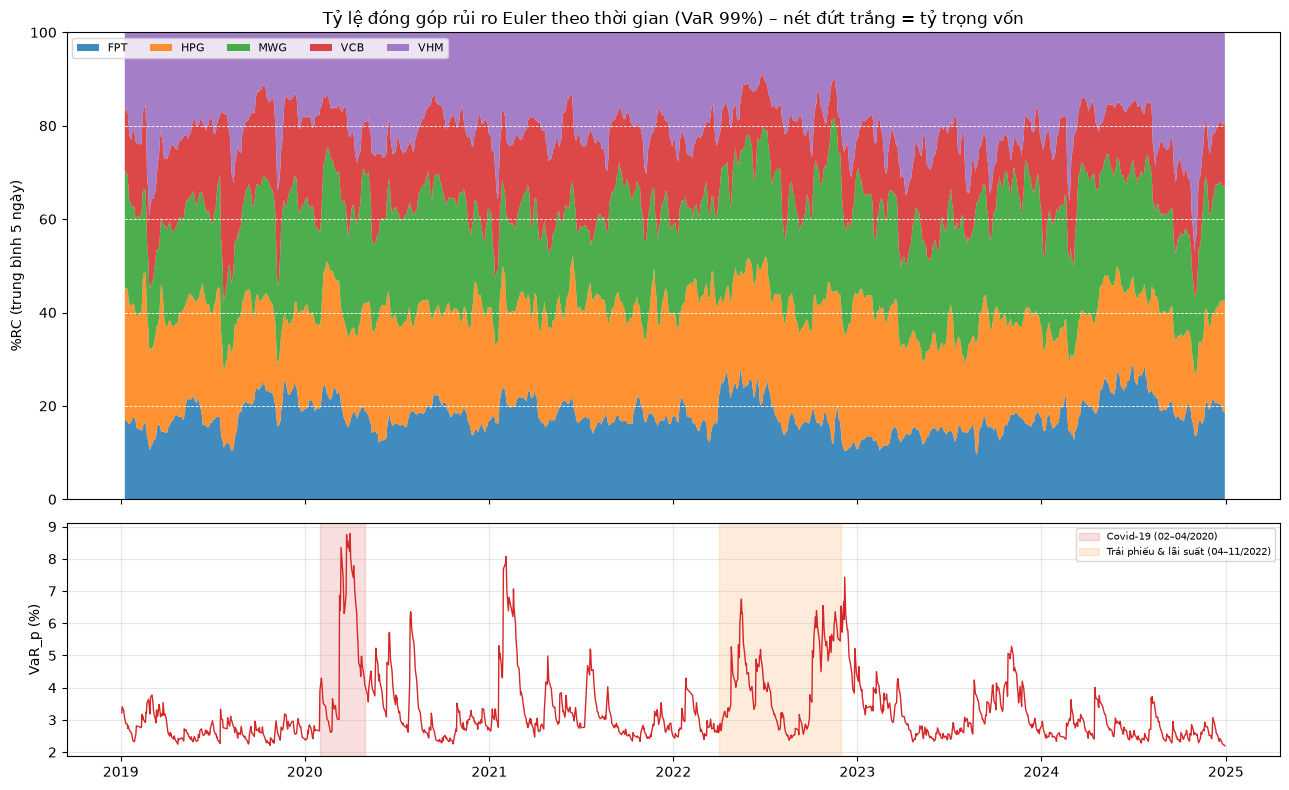

In [ ]:
# Đồ thị %RC theo thời gian (stacked) + VaR danh mục
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
pr_s = pd.DataFrame(PRC * 100, index=dates, columns=tickers).rolling(5).mean()
axes[0].stackplot(dates, pr_s.T.values, labels=tickers, alpha=0.85)
for k, x in enumerate(np.cumsum(wv)[:-1] * 100):
    axes[0].axhline(x, color="white", lw=0.6, ls="--")
axes[0].set_ylim(0, 100); axes[0].set_ylabel("%RC (trung bình 5 ngày)")
axes[0].set_title(f"Tỷ lệ đóng góp rủi ro Euler theo thời gian (VaR {int(CL*100)}%) – nét đứt trắng = tỷ trọng vốn")
axes[0].legend(loc="upper left", ncol=N, fontsize=8)
axes[1].plot(dates, VaR_p * 100, color="tab:red", lw=1)
shade_stress(axes[1])
axes[1].set_ylabel("VaR_p (%)"); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT_DIR / "euler_rc_timeseries.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. Phân tích Stress Periods

**Tầng 1:** So sánh trung bình các chỉ tiêu trong từng giai đoạn với giai đoạn **bình thường** (ngoài mọi giai đoạn khủng hoảng):
σ_p, VaR_p, %RC_i, tương quan trung bình, **hệ số đa dạng hoá** $DR_t = \dfrac{\sum_i w_i\sigma_{i,t}}{\sigma_{p,t}}$ (DR = 1 ⇒ không còn lợi ích đa dạng hoá), tỷ lệ vi phạm VaR (từ TV4).

**Tầng 3:** %RC tăng mạnh nhất trong khủng hoảng ⇒ mã "khuếch đại" rủi ro hệ thống. DR giảm + tương quan tăng ⇒ **correlation breakdown**.

In [ ]:
masks = {"Bình thường": np.ones(T, dtype=bool)}
for name, (a, b) in STRESS_PERIODS.items():
    m = (dates >= a) & (dates <= b)
    masks[name] = m
    masks["Bình thường"] &= ~m

iu = np.triu_indices(N, 1)
avg_corr_t = R[:, iu[0], iu[1]].mean(axis=1)
sig_i = np.sqrt(np.einsum("tii->ti", H))
DR_t = (sig_i @ wv) / sp_t
r_p = log_ret.values @ wv

summary_rows, prc_rows, mc_rows = {}, {}, {}
for name, m in masks.items():
    summary_rows[name] = {
        "Số phiên": int(m.sum()),
        "Lợi suất DM TB năm (%)": r_p[m].mean() * TRADING_DAYS * 100,
        "σ_p năm hoá (%)": sp_t[m].mean() * np.sqrt(TRADING_DAYS) * 100,
        f"VaR_p {int(CL*100)}% TB (%)": VaR_p[m].mean() * 100,
        "Lỗ lớn nhất 1 ngày (%)": -r_p[m].min() * 100,
        "Tương quan TB các cặp": avg_corr_t[m].mean(),
        "Hệ số đa dạng hoá DR": DR_t[m].mean(),
        "Lợi ích đa dạng hoá (1 − 1/DR, %)": (1 - 1 / DR_t[m]).mean() * 100,
        f"Tỷ lệ vi phạm VaR N {int(CL*100)}% (%)": (var_es["loss"].values[m] > var_es[f"VaR_Normal_{int(CL*100)}"].values[m]).mean() * 100,
    }
    prc_rows[name] = PRC[m].mean(axis=0) * 100
    mc_rows[name] = MC[m].mean(axis=0)
stress_summary = pd.DataFrame(summary_rows)
prc_period = pd.DataFrame(prc_rows, index=tickers)
prc_period.insert(0, "Tỷ trọng w (%)", wv * 100)
for name in STRESS_PERIODS:
    prc_period[f"Δ%RC {name} (điểm %)"] = prc_period[name] - prc_period["Bình thường"]
mc_period = pd.DataFrame(mc_rows, index=tickers)

print("Tổng quan danh mục theo giai đoạn:")
display(stress_summary.round(3))
print("Tỷ lệ đóng góp rủi ro %RC_i trung bình theo giai đoạn:")
display(prc_period.round(2))

Tổng quan danh mục theo giai đoạn:


,Bình thường,Covid-19 (02–04/2020),Trái phiếu & lãi suất (04–11/2022)
Số phiên,1224.000,61.000,167.000
Lợi suất DM TB năm (%),30.580,-84.785,-47.671
σ_p năm hoá (%),21.036,35.727,28.124
VaR_p 99% TB (%),3.083,5.236,4.121
Lỗ lớn nhất 1 ngày (%),7.215,7.212,5.007
Tương quan TB các cặp,0.358,0.459,0.378
Hệ số đa dạng hoá DR,1.434,1.324,1.396
"Lợi ích đa dạng hoá (1 − 1/DR, %)",30.101,24.236,28.241
Tỷ lệ vi phạm VaR N 99% (%),1.144,4.918,2.994


Tỷ lệ đóng góp rủi ro %RC_i trung bình theo giai đoạn:


,Tỷ trọng w (%),Bình thường,Covid-19 (02–04/2020),Trái phiếu & lãi suất (04–11/2022),Δ%RC Covid-19 (02–04/2020) (điểm %),Δ%RC Trái phiếu & lãi suất (04–11/2022) (điểm %)
FPT,20.0,17.67,20.10,19.60,2.43,1.93
HPG,20.0,22.22,22.15,24.44,-0.07,2.22
MWG,20.0,22.23,24.59,26.18,2.36,3.95
VCB,20.0,15.78,14.45,13.58,-1.33,-2.21
VHM,20.0,22.09,18.70,16.20,-3.39,-5.89


In [ ]:
# Trả lời trực tiếp các câu hỏi phân tích
answers = []
for name in STRESS_PERIODS:
    col = prc_period[name]
    d = prc_period[f"Δ%RC {name} (điểm %)"]
    s, nrm = stress_summary[name], stress_summary["Bình thường"]
    answers.append(
        f"[{name}]\n"
        f"  • Đóng góp rủi ro lớn nhất: {col.idxmax()} ({col.max():.1f}% VaR, tỷ trọng {w[col.idxmax()]*100:.0f}%).\n"
        f"  • Tăng đóng góp mạnh nhất so với bình thường: {d.idxmax()} ({d.max():+.1f} điểm %); "
        f"giảm mạnh nhất: {d.idxmin()} ({d.min():+.1f} điểm %).\n"
        f"  • σ_p năm hoá: {nrm['σ_p năm hoá (%)']:.1f}% → {s['σ_p năm hoá (%)']:.1f}%; "
        f"VaR99 TB: {nrm[f'VaR_p {int(CL*100)}% TB (%)']:.2f}% → {s[f'VaR_p {int(CL*100)}% TB (%)']:.2f}%.\n"
        f"  • Tương quan TB: {nrm['Tương quan TB các cặp']:.3f} → {s['Tương quan TB các cặp']:.3f}; "
        f"lợi ích đa dạng hoá: {nrm['Lợi ích đa dạng hoá (1 − 1/DR, %)']:.1f}% → {s['Lợi ích đa dạng hoá (1 − 1/DR, %)']:.1f}%"
        f" ({'GIẢM' if s['Lợi ích đa dạng hoá (1 − 1/DR, %)'] < nrm['Lợi ích đa dạng hoá (1 − 1/DR, %)'] else 'không giảm'}).")
print("\n\n".join(answers))

[Covid-19 (02–04/2020)]
  • Đóng góp rủi ro lớn nhất: MWG (24.6% VaR, tỷ trọng 20%).
  • Tăng đóng góp mạnh nhất so với bình thường: FPT (+2.4 điểm %); giảm mạnh nhất: VHM (-3.4 điểm %).
  • σ_p năm hoá: 21.0% → 35.7%; VaR99 TB: 3.08% → 5.24%.
  • Tương quan TB: 0.358 → 0.459; lợi ích đa dạng hoá: 30.1% → 24.2% (GIẢM).

[Trái phiếu & lãi suất (04–11/2022)]
  • Đóng góp rủi ro lớn nhất: MWG (26.2% VaR, tỷ trọng 20%).
  • Tăng đóng góp mạnh nhất so với bình thường: MWG (+3.9 điểm %); giảm mạnh nhất: VHM (-5.9 điểm %).
  • σ_p năm hoá: 21.0% → 28.1%; VaR99 TB: 3.08% → 4.12%.
  • Tương quan TB: 0.358 → 0.378; lợi ích đa dạng hoá: 30.1% → 28.2% (GIẢM).


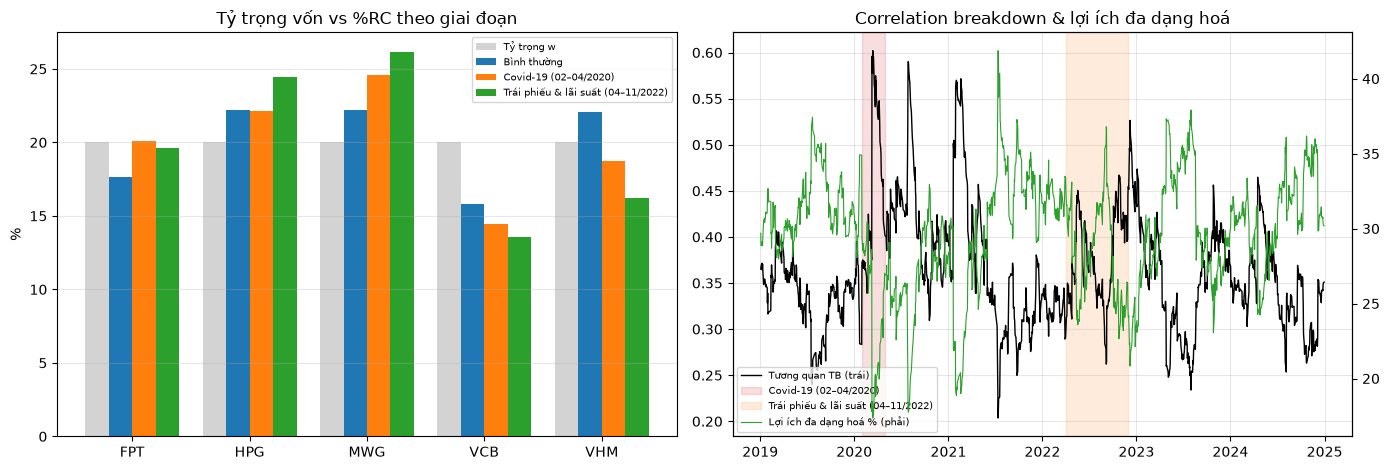

In [ ]:
# Đồ thị so sánh %RC theo giai đoạn + tương quan / đa dạng hoá theo thời gian
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
cols = ["Bình thường"] + list(STRESS_PERIODS)
x = np.arange(N); width = 0.8 / (len(cols) + 1)
axes[0].bar(x - width * len(cols) / 2, wv * 100, width, color="lightgrey", label="Tỷ trọng w")
for k, c in enumerate(cols):
    axes[0].bar(x - width * len(cols) / 2 + width * (k + 1), prc_period[c], width, label=c)
axes[0].set_xticks(x); axes[0].set_xticklabels(tickers); axes[0].set_ylabel("%")
axes[0].set_title("Tỷ trọng vốn vs %RC theo giai đoạn"); axes[0].legend(fontsize=7); axes[0].grid(alpha=0.3, axis="y")

ax2 = axes[1]
ax2.plot(dates, avg_corr_t, color="black", lw=1, label="Tương quan TB (trái)")
shade_stress(ax2)
ax3 = ax2.twinx()
ax3.plot(dates, (1 - 1 / DR_t) * 100, color="tab:green", lw=0.8, label="Lợi ích đa dạng hoá % (phải)")
ax2.set_title("Correlation breakdown & lợi ích đa dạng hoá"); ax2.grid(alpha=0.3)
h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = ax3.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, fontsize=7, loc="lower left")
plt.tight_layout(); plt.savefig(OUT_DIR / "stress_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

### 2b. Tác động thuần của tương quan (correlation breakdown) lên Euler contribution
Giữ nguyên biến động hiện tại (dự báo T+1) nhưng thay ma trận tương quan bằng **tương quan trung bình của từng giai đoạn khủng hoảng** ⇒ tách riêng phần VaR tăng do tương quan.

In [ ]:
sig_f = np.sqrt(np.diag(H_fcst))
scen = {}
for name, m in masks.items():
    Rm = R[m].mean(axis=0)
    Hs = sig_f[:, None] * Rm * sig_f[None, :]
    v, mc, rc, prc = euler(Hs, wv)
    scen[f"σ hiện tại + ρ {name}"] = {"VaR_p (%)": v * 100, **{f"%RC {t}": p * 100 for t, p in zip(tickers, prc)}}
Hs1 = sig_f[:, None] * np.ones((N, N)) * sig_f[None, :]
v1 = zq * np.sqrt(wv @ Hs1 @ wv)
scen["σ hiện tại + ρ = 1 (tệ nhất)"] = {"VaR_p (%)": v1 * 100, **{f"%RC {t}": wv[i] * sig_f[i] / (wv @ sig_f) * 100 for i, t in enumerate(tickers)}}
corr_scen = pd.DataFrame(scen).T
display(corr_scen.round(3))

,VaR_p (%),%RC FPT,%RC HPG,%RC MWG,%RC VCB,%RC VHM
σ hiện tại + ρ Bình thường,2.163,18.886,22.895,24.649,14.412,19.158
σ hiện tại + ρ Covid-19 (02–04/2020),2.339,18.211,22.750,25.010,14.665,19.364
σ hiện tại + ρ Trái phiếu & lãi suất (04–11/2022),2.201,18.903,22.330,25.267,14.130,19.370
σ hiện tại + ρ = 1 (tệ nhất),3.090,18.092,21.842,23.533,16.258,20.275


## 3. Khuyến nghị quản trị – danh mục cân bằng rủi ro (Equal Risk Contribution)
**Tầng 1:** Tìm w* sao cho $\%RC_i = 1/N$ với mọi i (risk parity), dùng $H_{T+1}$ (hiện tại) và $\bar H$ của giai đoạn khủng hoảng.
Thuật toán lặp: $w_i \leftarrow w_i \cdot \dfrac{1/N}{\%RC_i}$ rồi chuẩn hoá tổng = 1 (hội tụ nhanh với ma trận hiệp phương sai dương).
So sánh w* với w hiện tại cho biết **nên giảm/tăng tỷ trọng mã nào** để kiểm soát tập trung rủi ro.

In [ ]:
def risk_parity(Hm, n_iter=500, tol=1e-12):
    x = np.ones(Hm.shape[0]) / Hm.shape[0]
    for _ in range(n_iter):
        prc = x * (Hm @ x) / (x @ Hm @ x)
        x_new = x * (1 / len(x)) / prc
        x_new /= x_new.sum()
        if np.max(np.abs(x_new - x)) < tol:
            break
        x = x_new
    return x_new


rp_rows = {"w hiện tại (%)": wv * 100}
for label, Hm in [("ERC theo H_{T+1}", H_fcst)] + \
                 [(f"ERC theo H TB {n}", H[m].mean(axis=0)) for n, m in masks.items() if n != "Bình thường"]:
    x_rp = risk_parity(Hm)
    rp_rows[f"{label} (%)"] = x_rp * 100
rp_table = pd.DataFrame(rp_rows, index=tickers)
rp_table["%RC hiện tại (T+1)"] = euler(H_fcst, wv)[3] * 100
v_cur = euler(H_fcst, wv)[0]
v_rp = euler(H_fcst, rp_table["ERC theo H_{T+1} (%)"].values / 100)[0]
display(rp_table.round(2))
print(f"VaR_p {int(CL*100)}% (T+1): hiện tại = {v_cur:.3%} | danh mục ERC = {v_rp:.3%}")

,w hiện tại (%),ERC theo H_{T+1} (%),ERC theo H TB Covid-19 (02–04/2020) (%),ERC theo H TB Trái phiếu & lãi suất (04–11/2022) (%),%RC hiện tại (T+1)
FPT,20.0,21.17,21.21,19.47,18.30
HPG,20.0,16.99,19.55,15.66,23.61
MWG,20.0,16.13,16.54,14.61,25.28
VCB,20.0,25.35,23.39,27.15,14.10
VHM,20.0,20.36,19.31,23.11,18.71


VaR_p 99% (T+1): hiện tại = 2.155% | danh mục ERC = 2.092%


In [ ]:
# ===================== KHUYẾN NGHỊ TỰ ĐỘNG (làm dàn ý cho phần thuyết trình) =====================
top_now = tbl_fcst.drop("TỔNG")["%RC_i − w_i (điểm %)"]
over = top_now[top_now > 1].sort_values(ascending=False)
under = top_now[top_now < -1].sort_values()
nrm = stress_summary["Bình thường"]
lines = ["KHUYẾN NGHỊ QUẢN TRỊ RỦI RO (tự động sinh từ kết quả – cần biên tập lại khi viết báo cáo)", "=" * 80]
lines.append(f"1. Tập trung rủi ro hiện tại (T+1): " + (
    ", ".join(f"{t} gánh {tbl_fcst.loc[t, '%RC_i']:.1f}% rủi ro với {w[t]*100:.0f}% vốn" for t in over.index)
    if len(over) else "không mã nào vượt tỷ trọng vốn quá 1 điểm %.") +
    (" -> ứng viên GIẢM tỷ trọng." if len(over) else ""))
if len(under):
    lines.append("   Mã đóng góp rủi ro thấp hơn tỷ trọng (đa dạng hoá tốt): " + ", ".join(under.index) + ".")
for k, name in enumerate(STRESS_PERIODS):
    s = stress_summary[name]
    d = prc_period[f"Δ%RC {name} (điểm %)"]
    lines.append(f"2{'abcdef'[k]}. {name}: σ_p tăng {s['σ_p năm hoá (%)'] / nrm['σ_p năm hoá (%)']:.2f} lần, tương quan TB "
                 f"{nrm['Tương quan TB các cặp']:.2f} → {s['Tương quan TB các cặp']:.2f}, lợi ích đa dạng hoá "
                 f"{nrm['Lợi ích đa dạng hoá (1 − 1/DR, %)']:.1f}% → {s['Lợi ích đa dạng hoá (1 − 1/DR, %)']:.1f}%; "
                 f"{d.idxmax()} tăng đóng góp mạnh nhất ({d.max():+.1f} điểm %).")
lines += [
    "3. Khi thị trường vào giai đoạn căng thẳng (σ_p hoặc tương quan TB vượt ngưỡng lịch sử): giảm tỷ trọng các mã có "
    "%RC − w lớn nhất, chuyển dần về danh mục ERC (bảng risk parity), và/hoặc giảm tổng mức đầu tư thay vì chỉ hoán đổi mã "
    "vì tương quan tăng làm đa dạng hoá giữa cổ phiếu trong nước kém hiệu quả.",
    "4. Đa dạng hoá ngành: nên tăng (mã khác ngành có tương quan thấp), NHƯNG lợi ích này suy giảm trong khủng hoảng "
    "(xem DR) -> cần bổ sung tài sản ít tương quan hơn (trái phiếu chính phủ, tiền gửi, vàng) cho kịch bản stress.",
    "5. Dùng Euler RC như hạn mức: đặt trần %RC_i (ví dụ ≤ 30% VaR) cho từng mã, theo dõi hằng ngày bằng H_t từ DCC; "
    "vượt trần -> tái cân bằng. Kết hợp kết quả backtest TV4: " +
    "; ".join(f"{r['Phương pháp']} {r['Mức tin cậy']}: {int(r['Vi phạm thực tế'])}/{r['Vi phạm kỳ vọng']:.0f} vi phạm "
              f"({r['Đánh giá']})" for _, r in bt_table[bt_table["Mức tin cậy"] == f"{int(CL*100)}%"].iterrows()) + ".",
]
rec_text = "\n".join(lines)
print(rec_text)
(OUT_DIR / "recommendations.txt").write_text(rec_text, encoding="utf-8")

with pd.ExcelWriter(OUT_DIR / "TV5_euler_stress.xlsx", engine="openpyxl") as xw:
    integration.to_excel(xw, sheet_name="Kiem_tra_tich_hop", index=False)
    tbl_fcst.to_excel(xw, sheet_name="Euler_T+1")
    stress_summary.to_excel(xw, sheet_name="Stress_tong_quan")
    prc_period.to_excel(xw, sheet_name="PctRC_theo_giai_doan")
    mc_period.to_excel(xw, sheet_name="MC_VaR_theo_giai_doan")
    corr_scen.to_excel(xw, sheet_name="Kich_ban_tuong_quan")
    rp_table.to_excel(xw, sheet_name="Risk_parity")
print("✔ Đã lưu kết quả TV5 vào:", OUT_DIR)

KHUYẾN NGHỊ QUẢN TRỊ RỦI RO (tự động sinh từ kết quả – cần biên tập lại khi viết báo cáo)
1. Tập trung rủi ro hiện tại (T+1): MWG gánh 25.3% rủi ro với 20% vốn, HPG gánh 23.6% rủi ro với 20% vốn -> ứng viên GIẢM tỷ trọng.
   Mã đóng góp rủi ro thấp hơn tỷ trọng (đa dạng hoá tốt): VCB, FPT, VHM.
2a. Covid-19 (02–04/2020): σ_p tăng 1.70 lần, tương quan TB 0.36 → 0.46, lợi ích đa dạng hoá 30.1% → 24.2%; FPT tăng đóng góp mạnh nhất (+2.4 điểm %).
2b. Trái phiếu & lãi suất (04–11/2022): σ_p tăng 1.34 lần, tương quan TB 0.36 → 0.38, lợi ích đa dạng hoá 30.1% → 28.2%; MWG tăng đóng góp mạnh nhất (+3.9 điểm %).
3. Khi thị trường vào giai đoạn căng thẳng (σ_p hoặc tương quan TB vượt ngưỡng lịch sử): giảm tỷ trọng các mã có %RC − w lớn nhất, chuyển dần về danh mục ERC (bảng risk parity), và/hoặc giảm tổng mức đầu tư thay vì chỉ hoán đổi mã vì tương quan tăng làm đa dạng hoá giữa cổ phiếu trong nước kém hiệu quả.
4. Đa dạng hoá ngành: nên tăng (mã khác ngành có tương quan thấp), NHƯNG lợi ích này

## 4. Gợi ý trả lời vấn đáp
**Câu 1 – Vì sao mã có tỷ trọng nhỏ vẫn có thể đóng góp rủi ro lớn nhất?** Vì $\%RC_i = w_i\,\beta_{i,p}$ với $\beta_{i,p}=\dfrac{(Hw)_i}{w'Hw}$: đóng góp = tỷ trọng × **độ nhạy với danh mục**. Một mã biến động rất cao và tương quan cao với các mã còn lại có β lớn, nên dù w nhỏ, RC vẫn có thể vượt mã tỷ trọng lớn nhưng biến động thấp/ít tương quan. Tỷ trọng vốn ≠ tỷ trọng rủi ro.

**Câu 2 – Correlation breakdown ảnh hưởng thế nào đến Euler contribution?** Khi tương quan tăng vọt, $(H_tw)_i$ tăng với mọi i ⇒ $\sigma_p$ và VaR_p tăng (lợi ích đa dạng hoá mất đi, DR → 1), đồng thời %RC dịch chuyển về các mã **biến động cao nhất** (giới hạn ρ = 1: $\%RC_i = w_i\sigma_i/\sum_j w_j\sigma_j$). Các mã vốn "phòng hộ" nhờ tương quan thấp mất vai trò đó. Hệ quả: hạn mức rủi ro đặt theo giai đoạn bình thường sẽ bị vượt đồng loạt – cần stress test bằng ma trận tương quan khủng hoảng (mục 2b).